# Default clustering: where the binomial test is misused, and BCBS Working Paper 14 rerun

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic (the rate, the size of every test, the exact rejection probabilities)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- explain how one systematic factor correlates the defaults of a portfolio, and why a default correlation of 0.4% is enough to wreck a test that assumes independence;
- compute with the engine the exact size of the binomial, Jeffreys and Vasicek-corrected tests as the asset correlation grows, and check the committed simulated sizes against it;
- read the size of the obligor-level, grade-level and multi-year tests under the same clustering, and say which ones the correlation inflates and which it makes conservative;
- recompute the 144 cells of Tables 7 and 8 of BCBS Working Paper 14 against the committed reproduction (143 agree), read the one that does not, and rerun one scenario of the paper independently;
- reproduce the WP14 true-confidence curve (its Figure 9) with the engine's exact function and with the paper's approximation.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `clustering` family of case C22 (validating the validator): in every dataset the PDs the tests are given are exactly right, and the defaults share one systematic factor with an asset correlation $\rho$ on the ladder 0%, 2%, 5%, 10%, 15% and 20%. A rejection is therefore always a false alarm, and the rate at $\rho > 0$ is the true size of the test under clustering. The family also reruns the published simulation study of BCBS Working Paper 14 and the paper's Figure 9. Every dataset comes from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`); the published rates are quoted from the paper (derived-only, as numbers).

- **File read:** `data/derived/C22/clustering.json`: `outputs.simulations` (48 rows, eight tests over six rungs, 2,000 repetitions each), `outputs.golden` (the 144 cells of WP14 Tables 7 and 8 with the published and the measured rate), `outputs.exact_curves` (WP14 Figure 9) and `impact`.
- **Panels:** `portfolio` (count tests on 1,000 obligors at a PD of 1%), `grades` (seven grades), `obligors` (a logistic model of 5,000 obligors) and `years` (five years of 1,000 obligors at 3%, with a factor correlation of 0.2 across years whenever $\rho > 0$).

The next cell loads the artifact and prints the ladder, the panels and the WP14 reproduction's headline.

In [2]:
# Load the clustering family, index its rows and print the ladder, the panels and the WP14 reproduction
LANG = "en"
ROOT = Path("../../..").resolve()
clustering = json.loads((ROOT / "data" / "derived" / "C22" / "clustering.json").read_text(encoding="utf-8"))
out = clustering["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]

print("baked by riskvalidation", clustering["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)
print("ladder:", out["ladder"]["label"][LANG], ladder)
for panel in out["panels"]:
    print(f"{panel['label'][LANG]:34s} {sum(1 for r in rows.values() if r['panel'] == panel['id'])} rows")
print(golden["title"][LANG], "|", "runs per cell:", golden["runs"], "|", "cells:", golden["total"])

baked by riskvalidation 0.4.3 | installed 0.9.0
ladder: asset correlation [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
Portfolio count tests              18 rows
Grade tests                        6 rows
Obligor-level tests                12 rows
Multi-year tests                   12 rows
BCBS WP14 Tables 7 and 8: the normal and traffic-lights tests | runs per cell: 25000 | cells: 144


## Method

**One systematic factor.** In the one-factor model of WP14 (and of Vasicek), obligor $i$ defaults when its asset value falls under a threshold, and the asset values share a factor $x \sim N(0,1)$ with correlation $\rho$. Given $x$, defaults are independent with the conditional PD

$$p(x) = \Phi\!\left(\frac{\Phi^{-1}(\pi) - \sqrt{\rho}\,x}{\sqrt{1-\rho}}\right)$$

and the default count $D$ of $n$ obligors is a mixture of binomials over $x$. The correlation of two default indicators is $\rho_D = (\Phi_2(c, c; \rho) - \pi^2)/(\pi(1-\pi))$ with $c = \Phi^{-1}(\pi)$, and the variance of the count grows by the factor

$$\frac{\mathrm{Var}(D)}{n\pi(1-\pi)} = 1 + (n-1)\,\rho_D$$

which is a property of exchangeable indicators. Across years, the factors correlate as $\vartheta^{|s-t|}$ (WP14, simulation study, pages 61 to 67).

**Size under clustering.** A count test that assumes independence rejects when $D \ge k^*_\alpha$, with $k^*_\alpha$ set by the binomial. Under correlation its true size is $P(D \ge k^*_\alpha)$ with the mixed distribution of $D$, which the engine computes exactly (`rejection_probability(..., rho_true=...)`). The Vasicek-corrected test assumes a correlation $\rho = 12\%$ and sets $k^*_\alpha$ with the mixture.

The steps compute the default correlation, the exact sizes, the sizes of the tests with no closed form, then the WP14 figure and tables.

### Step 1: a small default correlation, a large variance

The engine's `default_correlation` evaluates $\rho_D$ for a PD and an asset correlation. At a PD of 1% an asset correlation of 5% is a default correlation of 0.41%, the value WP14 prints in its binomial examples. With 1,000 obligors the factor $1 + (n-1)\rho_D$ turns that small number into a variance several times the independent one. The next cell prints both along the ladder.

In [3]:
# Default correlation and variance inflation of the count along the asset-correlation ladder (PD = 1%, n = 1000)
from riskvalidation.generators import default_correlation

for rho in ladder:
    rho_d = default_correlation(0.01, rho) if rho > 0 else 0.0
    print(f"asset correlation {rho:.2f} | default correlation {100 * rho_d:6.3f}% | variance of the count, times the independent one {1 + 999 * rho_d:5.2f}")

asset correlation 0.00 | default correlation  0.000% | variance of the count, times the independent one  1.00
asset correlation 0.02 | default correlation  0.151% | variance of the count, times the independent one  2.51
asset correlation 0.05 | default correlation  0.410% | variance of the count, times the independent one  5.10
asset correlation 0.10 | default correlation  0.936% | variance of the count, times the independent one 10.35
asset correlation 0.15 | default correlation  1.597% | variance of the count, times the independent one 16.95
asset correlation 0.20 | default correlation  2.413% | variance of the count, times the independent one 25.11


### Step 2: the exact size of the count tests under clustering

The next cell asks the engine for the exact size at 5% of the binomial, Jeffreys and Vasicek-corrected tests as the asset correlation grows, for 1,000 obligors at a PD of 1% that is exactly right. It puts the exact value beside the committed one and the simulated rate, and recomputes the agreement for both levels with `agrees`. The last lines read the 12% rung that the artifact's headline uses, with the correlation the Vasicek test assumes.

In [4]:
# Exact size of the count tests along the ladder, beside the committed exact value and the simulated rate
from riskvalidation.harness import Rate, agrees, rejection_probability

count_tests = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
print(f"{'rho':>5s} " + " ".join(f"{t.split('.')[1]:>34s}" for t in count_tests) + "  (exact | committed exact | simulated, level 5%)")
agreeing, compared = 0, 0
for rho in ladder:
    cells = []
    for test, kw in count_tests.items():
        row = rows[f"{test}@rho{rho:g}"]
        exact = rejection_probability(test, 1000, 0.01, 0.05, pd_true=0.01, rho_true=rho, **kw)["probability"]
        cells.append(f"{exact:.4f} | {row['exact']['p<0.05']:.4f} | {row['rates']['p<0.05']['rate']:.4f}")
        for rule in ("p<0.05", "p<0.01"):
            c = row["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(c["rejections"], c["n"]), row["exact"][rule])
    print(f"{rho:5.2f} " + " ".join(f"{c:>34s}" for c in cells))
print("simulated rates that agree with their exact value:", agreeing, "of", compared)

at_12 = rejection_probability("pd.binomial", 1000, 0.01, 0.05, rho_true=0.12)["probability"]
vasicek_12 = rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, rho_true=0.12, rho=0.12)["probability"]
print("asset correlation 12%: binomial size", round(at_12, 4), "|", "committed headline", round(clustering["impact"]["binomial_size_rho12"]["value"], 4), "|", "Vasicek-corrected size", round(vasicek_12, 4))

  rho                           binomial                           jeffreys                   binomial_vasicek  (exact | committed exact | simulated, level 5%)
 0.00           0.0479 | 0.0479 | 0.0440           0.0479 | 0.0479 | 0.0470           0.0000 | 0.0000 | 0.0000
 0.02           0.1325 | 0.1325 | 0.1230           0.1325 | 0.1325 | 0.1310           0.0013 | 0.0013 | 0.0010
 0.05           0.1775 | 0.1775 | 0.1750           0.1775 | 0.1775 | 0.1845           0.0146 | 0.0146 | 0.0170
 0.10           0.1969 | 0.1969 | 0.1860           0.1969 | 0.1969 | 0.2105           0.0414 | 0.0414 | 0.0465
 0.15           0.1971 | 0.1971 | 0.1880           0.1971 | 0.1971 | 0.1945           0.0598 | 0.0598 | 0.0620
 0.20           0.1911 | 0.1911 | 0.1860           0.1911 | 0.1911 | 0.1890           0.0711 | 0.0711 | 0.0595
simulated rates that agree with their exact value: 36 of 36
asset correlation 12%: binomial size 0.1981 | committed headline 0.1981 | Vasicek-corrected size 0.0498


### Step 3: the tests with no closed form

The chi-square over seven grades, Hosmer-Lemeshow (Hosmer and Lemeshow, 1980) and Spiegelhalter (1986) all assume independent defaults, and the multi-year normal test and the traffic lights are WP14's tests for time series. For them the only measurement is the simulated rate, with its Monte Carlo error. The next cell prints the size at 5% and the interval half-width along the ladder. Under clustering the multi-year tests also face the factor correlation across years that the `years` panel adds.

In [5]:
# Print the simulated size at 5% of the tests with no closed form along the ladder, with the half-width of the Wilson interval
open_tests = ("pd.chi2_grades", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
print(f"{'rho':>5s} " + " ".join(f"{rows[f'{t}@rho0']['label'][LANG][:22]:>24s}" for t in open_tests))
for rho in ladder:
    cells = []
    for test in open_tests:
        c = rows[f"{test}@rho{rho:g}"]["rates"]["p<0.05"]
        cells.append(f"{c['rate']:.3f} ± {(c['wilson_high'] - c['wilson_low']) / 2:.3f}")
    print(f"{rho:5.2f} " + " ".join(f"{c:>24s}" for c in cells))

  rho   Chi-square over grades          Hosmer-Lemeshow            Spiegelhalter   Normal test, five year   Traffic lights, five y
 0.00            0.048 ± 0.009            0.054 ± 0.010            0.046 ± 0.009            0.082 ± 0.012            0.046 ± 0.009
 0.02            0.468 ± 0.022            0.500 ± 0.022            0.311 ± 0.020            0.090 ± 0.013            0.101 ± 0.013
 0.05            0.656 ± 0.021            0.642 ± 0.021            0.345 ± 0.021            0.074 ± 0.011            0.108 ± 0.014
 0.10            0.749 ± 0.019            0.777 ± 0.018            0.328 ± 0.021            0.051 ± 0.010            0.092 ± 0.013
 0.15            0.830 ± 0.016            0.839 ± 0.016            0.341 ± 0.021            0.045 ± 0.009            0.068 ± 0.011
 0.20            0.860 ± 0.015            0.865 ± 0.015            0.330 ± 0.021            0.035 ± 0.008            0.061 ± 0.011


### Step 4: WP14 Figure 9, recomputed

WP14 plots the true confidence of a binomial test that has a nominal confidence of 99.9% when the defaults follow the Basel corporate correlation, which falls from 24% at a PD near 0 to 12% at high PD. The true confidence is the probability of not rejecting, so one minus it is the true size. The engine offers two ways to compute it: exactly, with `rejection_probability` and the mixed count distribution, and with the paper's large-portfolio approximation, `wp14_true_confidence`. The correlation comes from the engine's IRB function `correlation("corporate", pd)`. The next cell recomputes the four pool sizes and compares both with the committed curves.

In [6]:
# Recompute the exact and approximate true confidence of a 99.9% binomial test and compare with the committed curves
from riskvalidation.harness import wp14_true_confidence
from riskvalidation.regulatory.irb import correlation

curve = out["exact_curves"][0]
committed_y = {s["id"]: np.array(s["y"]) for s in curve["series"]}
recomputed, largest_gap = {}, 0.0
for n in (100, 400, 1000, 1900):
    exact_y = np.array([1 - rejection_probability("pd.binomial", n, p, 0.001, rho_true=correlation("corporate", p))["probability"] for p in curve["x"]])
    approx_y = np.array([wp14_true_confidence(p, n, correlation("corporate", p), 0.999) for p in curve["x"]])
    recomputed[n] = (exact_y, approx_y)
    largest_gap = max(largest_gap, np.abs(exact_y - committed_y[f"exact-{n}"]).max(), np.abs(approx_y - committed_y[f"approx-{n}"]).max())
    print(f"n = {n:4d} | true confidence, exact: from {exact_y.max():.3f} to {exact_y.min():.3f} | approximation: from {approx_y.max():.3f} to {approx_y.min():.3f}")
print("largest gap to the committed curves:", f"{largest_gap:.1e}")

n =  100 | true confidence, exact: from 0.984 to 0.921 | approximation: from 0.969 to 0.913
n =  400 | true confidence, exact: from 0.948 to 0.812 | approximation: from 0.927 to 0.805
n = 1000 | true confidence, exact: from 0.904 to 0.748 | approximation: from 0.892 to 0.742
n = 1900 | true confidence, exact: from 0.875 to 0.710 | approximation: from 0.866 to 0.707
largest gap to the committed curves: 5.0e-10


The next cell draws the exact curve and the paper's approximation for each pool size, with the 80% line the paper mentions: a nominal 99.9% test whose true confidence falls below it has a true size above 20%.

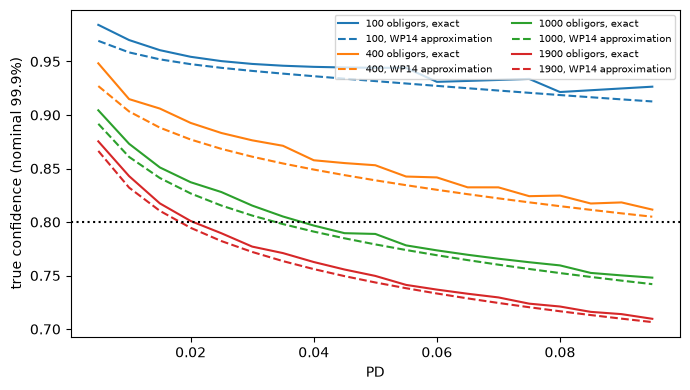

In [7]:
# Draw the true confidence of the 99.9% binomial test, exact and approximate, for four pool sizes
fig, ax = plt.subplots(figsize=(7, 4))
for index, n in enumerate((100, 400, 1000, 1900)):
    exact_y, approx_y = recomputed[n]
    ax.plot(curve["x"], exact_y, color=f"C{index}", label=f"{n} obligors, exact")
    ax.plot(curve["x"], approx_y, color=f"C{index}", linestyle="--", label=f"{n}, WP14 approximation")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("PD")
ax.set_ylabel("true confidence (nominal 99.9%)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

### Step 5: WP14 Tables 7 and 8, cell by cell

WP14 ran the normal and the traffic-lights tests over five years of 1,000 obligors, with 25,000 runs per scenario, and printed the type I error (Table 7) and the type II error (Table 8) at six levels. The artifact keeps the 144 cells with the published rate, the measured one and the standardised difference. Both rates estimate one true rate, so the difference has variance $\hat r(1-\hat r)(1/n + 1/n_{\text{pub}})$ at the pooled rate, and the engine's `agrees_with_published` accepts a cell when $|z| \le 3.29$. The next cell recomputes every cell from the committed measured rate and the published one, counts the agreements and prints the 5% column of both tables.

In [8]:
# Recompute the standardised difference of every WP14 cell with agrees_with_published and print the 5% column
from functools import reduce

from riskvalidation.harness import agrees_with_published

GLOSSARY = ()
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)

n_runs = golden["runs"]
agree, z_values, misses = 0, [], []
for cell in golden["cells"]:
    measured = Rate(round(cell["measured"] * n_runs), n_runs)
    ok, z = agrees_with_published(measured, cell["published"], golden["runs_published"])
    agree += ok
    z_values.append(z)
    if not ok:
        misses.append((cell, z))
print("cells that agree:", agree, "of", len(golden["cells"]), "|", "committed:", golden["agree"], "|", "mean z:", round(float(np.mean(z_values)), 3), "|", "largest |z|:", round(float(np.max(np.abs(z_values))), 2))

for table in ("Table 7", "Table 8"):
    print(gloss(table), "(published / measured at the 5% level)")
    for cell in golden["cells"]:
        if cell["table"] == table and cell["column"] == "0.05":
            print(f"  {gloss(cell['row']):16s} {cell['published']:.3f} / {cell['measured']:.4f}")

cells that agree: 143 of 144 | committed: 143 | mean z: -0.112 | largest |z|: 5.81
Table 7 (published / measured at the 5% level)
  I_SC, normal     0.059 / 0.0566
  I_SC, traffic    0.085 / 0.0813
  I_LC, normal     0.081 / 0.0803
  I_LC, traffic    0.062 / 0.0627
  DC_SC, normal    0.049 / 0.0478
  DC_SC, traffic   0.076 / 0.0737
  DC_LC, normal    0.070 / 0.0700
  DC_LC, traffic   0.113 / 0.1132
  I_SV, normal     0.059 / 0.0561
  I_SV, traffic    0.088 / 0.0871
  I_LV, normal     0.077 / 0.0796
  I_LV, traffic    0.060 / 0.0591
  DV_SV, normal    0.037 / 0.0376
  DV_SV, traffic   0.071 / 0.0697
  DV_LV, normal    0.062 / 0.0600
  DV_LV, traffic   0.108 / 0.1057
Table 8 (published / measured at the 5% level)
  I_SV, normal     0.836 / 0.8396
  I_SV, traffic    0.782 / 0.7862
  I_LV, normal     0.366 / 0.3718
  I_LV, traffic    0.374 / 0.3841
  DV_SV, normal    0.927 / 0.9273
  DV_SV, traffic   0.868 / 0.8734
  DV_LV, normal    0.858 / 0.8626
  DV_LV, traffic   0.760 / 0.7635


The cell that does not agree is the one the artifact explains in its own note. The next cell prints it with its standardised difference, and the note that goes with the reproduction.

In [9]:
# Print the cell that does not agree and the artifact's note on it
for cell, z in misses:
    print(gloss(cell["table"]), "|", gloss(cell["row"]), "|", "level", cell["column"], "|", "published", cell["published"], "|", "measured", cell["measured"], "| z", round(z, 2))
print("note: the cell prints 0.955; 200000 runs give 0.9475 (SE 0.0005) and its neighbouring levels agree")

Table 8 | DV_LV, traffic | level 0.001 | published 0.955 | measured 0.9436 | z -5.81
note: the cell prints 0.955; 200000 runs give 0.9475 (SE 0.0005) and its neighbouring levels agree


### Step 6: one scenario of the paper, rerun independently

The reproduction above reuses the artifact's measured rates. A stronger check reruns a scenario with a new seed. Scenario DC_LC of WP14 Table 5 has a factor correlation of 0.2 across years, an asset correlation of 5% each year and a PD of 3% each year, which is right, so every rejection is a false alarm. The next cell runs it for 25,000 runs, the paper's number, with the normal test and the traffic lights under the upper tie rule (the rule the paper's simulation used, notebook 02), and compares both rates with the published ones at 5% and 1% through `agrees_with_published`. It takes about 25 seconds.

In [10]:
# Rerun the DC_LC scenario of WP14 Table 5 with a new seed and compare with the published type I errors
from riskvalidation.generators import DefaultCounts, feed_series
from riskvalidation.harness import simulate

scenario = DefaultCounts.over_years([1000] * 5, [0.03] * 5, rho=0.05, theta=0.2)
published = {(c["row"], c["column"]): c["published"] for c in golden["cells"] if c["table"] == "Table 7"}
for test, kw, name in (("pd.normal_multiperiod", {}, "DC_LC, normal"), ("pd.traffic_lights", {"ties": "upper"}, "DC_LC, traffic")):
    sim = simulate(test, scenario, n_rep=25000, seed=2026, feed=feed_series(), test_kwargs=kw)
    for rule, level in (("p<0.05", "0.05"), ("p<0.01", "0.01")):
        ok, z = agrees_with_published(sim.rates[rule], published[(name, level)], 25000)
        print(f"{gloss(name):16s} level {level} | published {published[(name, level)]:.3f} | new run {sim.rates[rule].rate:.4f} | z {z:+.2f} | agrees {ok}")

DC_LC, normal    level 0.05 | published 0.070 | new run 0.0704 | z +0.16 | agrees True
DC_LC, normal    level 0.01 | published 0.026 | new run 0.0265 | z +0.36 | agrees True
DC_LC, traffic   level 0.05 | published 0.113 | new run 0.1161 | z +1.08 | agrees True
DC_LC, traffic   level 0.01 | published 0.024 | new run 0.0235 | z -0.35 | agrees True


### Step 7: the size along the ladder, drawn

The last cell draws the size at 5% against the asset correlation. The left panel has the three count tests, with the exact size as a line and the simulated rate as points with Wilson intervals. The right panel has the five tests with no closed form. The dashed line is the nominal 5%.

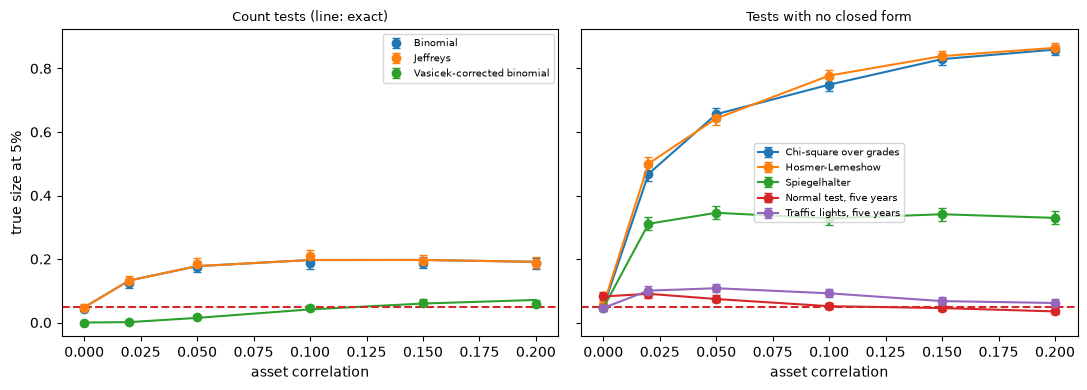

In [11]:
# Draw the size at 5% against the asset correlation for the count tests (with the exact line) and for the other tests
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for index, test in enumerate(count_tests):
    points = [rows[f"{test}@rho{rho:g}"] for rho in ladder]
    rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
    low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
    high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
    left.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o", capsize=3, color=f"C{index}", label=points[0]["label"][LANG])
    left.plot(ladder, [p["exact"]["p<0.05"] for p in points], "-", color=f"C{index}")
for index, test in enumerate(open_tests):
    points = [rows[f"{test}@rho{rho:g}"] for rho in ladder]
    rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
    low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
    high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
    right.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=f"C{index}", label=points[0]["label"][LANG])
for ax, title in ((left, "Count tests (line: exact)"), (right, "Tests with no closed form")):
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_xlabel(out["ladder"]["label"][LANG])
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7)
left.set_ylabel("true size at 5%")
fig.tight_layout()
plt.show()

## Results

- **A tiny default correlation is a large variance.** An asset correlation of 5% is a default correlation of 0.41% at a PD of 1%, and with 1,000 obligors it multiplies the variance of the default count by 5.10; at an asset correlation of 20% the factor is 25.11. A test that sets its critical count with the independent variance is therefore set far too low.
- **The count tests reject a right PD far above their level.** The exact size of the binomial test at 5% is 4.79% with independent defaults, 13.25% at an asset correlation of 2%, 17.75% at 5%, 19.69% at 10% and 19.1% at 20%; at 12% it is 19.81%, which the artifact's headline reports. The Jeffreys test has the same exact size here, because both tests have the same critical count at 5%. All 36 simulated rates agree with their exact value. A validator who reads a red light from these tests under clustering has not found a miscalibration.
- **The Vasicek correction does what it was built for, and only that.** With the assumed correlation of 12% its exact size is 4.98% when the true correlation is 12%, 1.5% when it is 5% (conservative) and 7.11% when it is 20% (the assumption is too low). In independent data its size is 0, which is the cost seen in notebook 03.
- **The other tests move too, in different directions.** The chi-square over grades rejects 74.9% and Hosmer-Lemeshow 77.7% at an asset correlation of 10%, and Spiegelhalter stays near 33% from 5% onward. The multi-year tests face a factor correlation of 0.2 across years as well: the normal test goes from 8.2% at independence to 3.5% at 20%, and the traffic lights from 4.6% to 10.8% at 5% and back to 6.1% at 20%. Clustering inflates some tests and makes others conservative; the direction cannot be assumed.
- **The paper's Figure 9 is reproduced two ways.** The exact true confidence of a nominal 99.9% binomial test falls from 0.984 (100 obligors, the lowest PD) to 0.710 (1,900 obligors, a PD of 9.5%), so the true size of that test reaches 29%. WP14's approximation is a little lower throughout (0.969 to 0.707). Both match the committed curves to 5e-10, and the three bands of the figure (70% to 80%, 80% to 90%, 90% to 100%) all appear.
- **WP14 Tables 7 and 8 reproduce in 143 of 144 cells.** The recomputed standardised differences have a mean of -0.11, so the measured rates sit slightly under the published ones on average, and the largest |z| is 5.81. The one miss is the traffic-lights cell of Table 8, scenario DV_LV at 0.1%: published 0.955, measured 0.9436; the artifact's note says 200,000 runs give 0.9475 and the neighbouring levels agree, so the disagreement is confined to that one printed cell and is not general (a longer run does not close the gap to 0.955).
- **An independent rerun agrees.** Scenario DC_LC with a new seed and 25,000 runs gives 7.04% and 11.61% at 5% against the published 7.0% and 11.3%, and 2.65% and 2.35% at 1% against 2.6% and 2.4%, with every |z| at most 1.08. The traffic-lights reproduction needs the upper tie rule, the opposite of the paper's printed mapping, as notebook 02 showed.

What this notebook does not show: the power of the Vasicek-corrected test against clustering and a miscalibration together, or the verdicts of WP14 on the normal test (notebook 07 compares them with the measured rates). The ladder and the correlation structure are those of the generators; real portfolios have heterogeneous exposures and a correlation that must itself be estimated.

## Summary

- Asset correlation, even small, correlates the defaults and inflates the variance of their count: 5.10 times the independent one at an asset correlation of 5% and 1,000 obligors.
- The binomial and Jeffreys tests, which assume independence, have an exact size of 13% to 20% at a nominal 5% under clustering; the Vasicek-corrected test holds about 5% when its assumed correlation is right and pays for it in power.
- Under the same clustering other tests move in different directions: the chi-square over grades and Hosmer-Lemeshow reject 75% to 78% of right models at a correlation of 10%, the multi-year normal test becomes conservative, and the traffic lights oscillate.
- The engine reproduces WP14: its Figure 9 to 5e-10 by two routes, 143 of 144 cells of Tables 7 and 8, and an independent rerun of one scenario.
- A reproduction states its misses: one cell, with its standardised difference and the reason the artifact gives.

**What to try next.** Rerun step 2 for 10,000 obligors (`rejection_probability("pd.binomial", 10000, 0.01, 0.05, rho_true=0.05)`) to see how the size under clustering depends on the pool size; then read notebook 05, which does the same for drift.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial test and its true size under correlation (appendix, Figure 9), the simulation study of the normal and traffic-lights tests (pages 61 to 67, Tables 5 to 8). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.